# 05 · Customer Segmentation (Model 2 — Clustering)

**Netflix Customer Intelligence, Churn Prediction & AI Analytics Copilot** · Week 2, Days 5–6

**Question:** what kinds of customers do we have, and which groups are valuable, fragile or both?

| | |
|---|---|
| **Method** | K-Means on engagement, billing, tenure, support and satisfaction features (PRD Section 11) |
| **Choosing K** | Elbow method **and** silhouette score |
| **Data** | The 2025-12-31 snapshot (6,939 active customers), so we can check afterwards whether the segments really differ in who went on to cancel |
| **Output** | Business-readable segment names, a profile table, and a segment for each of today's active customers (used by the Week 3 copilot) |

| Step | What happens |
|---|---|
| 1 | Load the features and choose which ones describe a customer's behaviour and value |
| 2 | Choose K (elbow + silhouette) |
| 3 | Fit the segments and test that they are stable |
| 4 | Profile and name each segment, with charts |
| 5 | Segment every active customer today, and save the model |
| 6 | Read the result |

In [1]:
PREFIX = "seg"

import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder that contains src/utils/config.py)
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src" / "utils" / "config.py").exists()), None)
if ROOT is None:                          # fallback: an environment variable set before starting Jupyter
    import os
    _env = os.environ.get("NETFLIX_PROJECT_ROOT", "")
    if _env and (Path(_env) / "src" / "utils" / "config.py").exists():
        ROOT = Path(_env).resolve()
assert ROOT is not None, (f"This notebook is running in {Path.cwd()}, which is not inside the project folder. "
                          "Open the copy in <project>/notebooks (start Jupyter from the project root), "
                          "or set the NETFLIX_PROJECT_ROOT environment variable.")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

PROCESSED = ROOT / "data" / "processed"
MODELS    = ROOT / "models"
REPORTS   = ROOT / "reports"
FIG_DIR   = REPORTS / "figures"
for d in (PROCESSED, MODELS, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

NETFLIX_RED, DARK, GREY, BLUE = "#E50914", "#221F1F", "#8C8C8C", "#3B6EA8"
sns.set_theme(style="whitegrid", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold", "axes.titlesize": 13})


def finish(num, name, fig=None):
    """Tidy the figure, save it to reports/figures and show it."""
    fig = fig or plt.gcf()
    fig.tight_layout()
    path = FIG_DIR / f"{PREFIX}_{num:02d}_{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"Saved chart: {path.relative_to(ROOT)}")

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
import joblib
from src.features import build_features as bf

RANDOM_STATE = 42
print("Setup done.")

Setup done.


## 1 · Data and features

In [2]:
read = lambda name: pd.read_csv(PROCESSED / name, index_col="customer_id", keep_default_na=False, na_values=[""])
train = read("customer_features_train.csv")
now = read("customer_features_current.csv")
TARGET = "churn_next_6m"

# Features that describe how a customer behaves and what they are worth (PRD: engagement, billing, tenure, satisfaction)
LOG_COLS = ["watch_min_90d", "sessions_90d", "support_ticket_count"]            # skewed counts -> log scale
LIN_COLS = ["customer_tenure_days", "avg_watch_time_per_session", "days_since_last_activity", "engagement_score",
            "failed_payment_rate", "avg_customer_satisfaction", "monthly_price", "customer_lifetime_value"]
SEG_FEATURES = LOG_COLS + LIN_COLS

prep = ColumnTransformer([
    ("log", Pipeline([("impute", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p)),
                      ("scale", StandardScaler())]), LOG_COLS),
    ("lin", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), LIN_COLS),
])
Z = prep.fit_transform(train[SEG_FEATURES])
print(f"{len(train):,} customers x {len(SEG_FEATURES)} features, standardised")

6,939 customers x 11 features, standardised


## 2 · Choosing K

Two checks for every K from 2 to 10:
- **Elbow:** within-cluster variance (inertia) always falls as K grows; we look for the bend after which extra clusters add little.
- **Silhouette:** how much closer a customer is to their own cluster than to the next one (−1 to 1; higher is better).

Customer behaviour is a continuum rather than a set of tight groups, so expect modest silhouette values. We look at K between 3 and 7 (fewer than 3 is not useful, more than 7 is not manageable for a business team). When several values of K have practically the same silhouette (within 0.01 of the best), we take the **largest** of them, because the extra segments cost nothing statistically and are more useful to the business.

In [3]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Z, km.labels_, sample_size=3000, random_state=RANDOM_STATE))
ktable = pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).set_index("k")
display(ktable.round(3))

,inertia,silhouette
k,,
2,57438.322,0.301
3,49368.812,0.202
4,45679.583,0.197
5,43257.834,0.179
6,41128.549,0.158
7,39034.598,0.157
8,37053.285,0.147
9,35777.484,0.143
10,34515.340,0.141


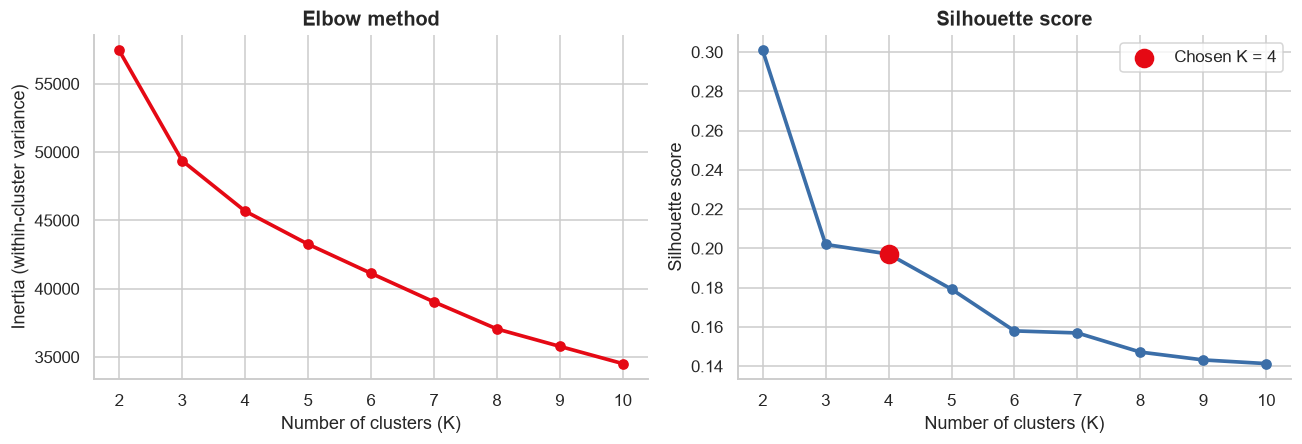

Saved chart: reports\figures\seg_01_choose_k.png
Best silhouette between K=3 and K=7: 0.202 (K=3).
Chosen K = 4 (silhouette 0.197): the largest K within 0.01 of the best, because equally good but richer segments are more useful. Set K by hand in this cell to override.


In [4]:
# Chart 1 — Elbow and silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(ktable.index, ktable.inertia, marker="o", color=NETFLIX_RED, lw=2.4)
axes[0].set_xlabel("Number of clusters (K)"); axes[0].set_ylabel("Inertia (within-cluster variance)"); axes[0].set_title("Elbow method")
axes[1].plot(ktable.index, ktable.silhouette, marker="o", color=BLUE, lw=2.4)
cand = ktable.loc[3:7, "silhouette"]
K = int(cand[cand >= cand.max() - 0.01].index.max())        # largest K whose silhouette is within 0.01 of the best
axes[1].scatter([K], [ktable.silhouette[K]], s=140, color=NETFLIX_RED, zorder=5, label=f"Chosen K = {K}")
axes[1].set_xlabel("Number of clusters (K)"); axes[1].set_ylabel("Silhouette score"); axes[1].set_title("Silhouette score"); axes[1].legend()
finish(1, "choose_k", fig)
print(f"Best silhouette between K=3 and K=7: {cand.max():.3f} (K={int(cand.idxmax())}).")
print(f"Chosen K = {K} (silhouette {ktable.silhouette[K]:.3f}): the largest K within 0.01 of the best, because equally good but richer segments are more useful. "
      "Set K by hand in this cell to override.")

## 3 · Fit the segments and check they are stable

In [5]:
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Z)
train["segment_id"] = kmeans.labels_

# Stability: do different random starts find the same segments? (1.0 = identical)
others = [KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(Z) for s in (1, 2, 3, 4)]
ari = np.mean([adjusted_rand_score(kmeans.labels_, o) for o in others])
print(f"Silhouette {silhouette_score(Z, kmeans.labels_, sample_size=3000, random_state=RANDOM_STATE):.3f} | "
      f"stability across random starts (adjusted Rand index) {ari:.2f}")
print(train.segment_id.value_counts().sort_index().to_string())

Silhouette 0.197 | stability across random starts (adjusted Rand index) 1.00
segment_id
0    2415
1     968
2    2158
3    1398


## 4 · Profile and name the segments

Each segment is described by how far its average customer sits from the overall average, in standard deviations (a **z-score**). The name is built from the two strongest traits, and a note is added if the segment really went on to churn more or less than average. **Read the profile table and rename any segment you think is better described differently** (see `NAME_OVERRIDES`).

In [6]:
overall = train[SEG_FEATURES].mean(); spread = train[SEG_FEATURES].std()
means = train.groupby("segment_id")[SEG_FEATURES].mean()
z = (means - overall) / spread

# Trait wording: (feature, +/-, label)
TRAITS = [("engagement_score", +1, "Highly Engaged"), ("engagement_score", -1, "Low-Engagement"),
          ("monthly_price", +1, "High-Value Plan"), ("monthly_price", -1, "Budget Plan"),
          ("customer_tenure_days", +1, "Long-Tenured"), ("customer_tenure_days", -1, "Newer"),
          ("failed_payment_rate", +1, "Billing-Trouble"), ("avg_customer_satisfaction", -1, "Dissatisfied"),
          ("support_ticket_count", +1, "Support-Heavy"), ("customer_lifetime_value", +1, "High-Spend"),
          ("customer_lifetime_value", -1, "Low-Spend")]
churn_rate = train.groupby("segment_id")[TARGET].mean(); base = train[TARGET].mean()

def name_segment(sid):
    cands = [(abs(z.loc[sid, f]), label) for f, sign, label in TRAITS if sign * z.loc[sid, f] >= 0.35]
    labels = [l for _, l in sorted(cands, reverse=True)][:2]
    name = ", ".join(labels) if labels else "Typical Customers"
    if churn_rate[sid] >= 1.15 * base: name += " (At-Risk)"
    elif churn_rate[sid] <= 0.85 * base: name += " (Stable)"
    return name

NAME_OVERRIDES = {}      # e.g. {0: "High-Value Loyal", 2: "At-Risk Low-Engagement"}
names = {sid: NAME_OVERRIDES.get(sid, name_segment(sid)) for sid in means.index}
if len(set(names.values())) < len(names):                       # make names unique
    seen = {}
    for sid, n in names.items():
        seen[n] = seen.get(n, 0) + 1
        if seen[n] > 1: names[sid] = f"{n} #{seen[n]}"
train["segment"] = train.segment_id.map(names)

profile = pd.DataFrame({
    "segment": pd.Series(names),
    "customers": train.groupby("segment_id").size(),
    "share_%": (train.groupby("segment_id").size() / len(train) * 100).round(1),
    "churn_next_6m_%": (churn_rate * 100).round(1),
    "avg_monthly_price": means.monthly_price.round(2),
    "MRR_share_%": (train.groupby("segment_id").monthly_price.sum() / train.monthly_price.sum() * 100).round(1),
    "avg_tenure_days": means.customer_tenure_days.round(0),
    "avg_engagement": means.engagement_score.round(1),
    "failed_payment_rate": means.failed_payment_rate.round(3),
    "avg_tickets": train.groupby("segment_id").support_ticket_count.mean().round(2),
    "avg_csat": means.avg_customer_satisfaction.round(2),
    "avg_lifetime_value": means.customer_lifetime_value.round(0),
})
profile.to_csv(REPORTS / "segment_profiles.csv", index=False)
display(profile.set_index("segment"))

,customers,share_%,churn_next_6m_%,avg_monthly_price,MRR_share_%,avg_tenure_days,avg_engagement,failed_payment_rate,avg_tickets,avg_csat,avg_lifetime_value
segment,,,,,,,,,,,
"High-Spend, High-Value Plan",2415,34.8,16.0,18.62,48.1,1358.0,53.6,0.050,0.43,2.60,253.0
"Support-Heavy, Highly Engaged",968,14.0,15.9,12.38,12.8,1386.0,54.8,0.075,1.64,4.13,164.0
"Low-Spend, Budget Plan (At-Risk)",2158,31.1,21.0,8.22,19.0,1136.0,55.9,0.082,0.37,2.46,89.0
Low-Engagement,1398,20.1,18.2,13.47,20.1,1254.0,1.4,0.052,0.59,3.26,175.0


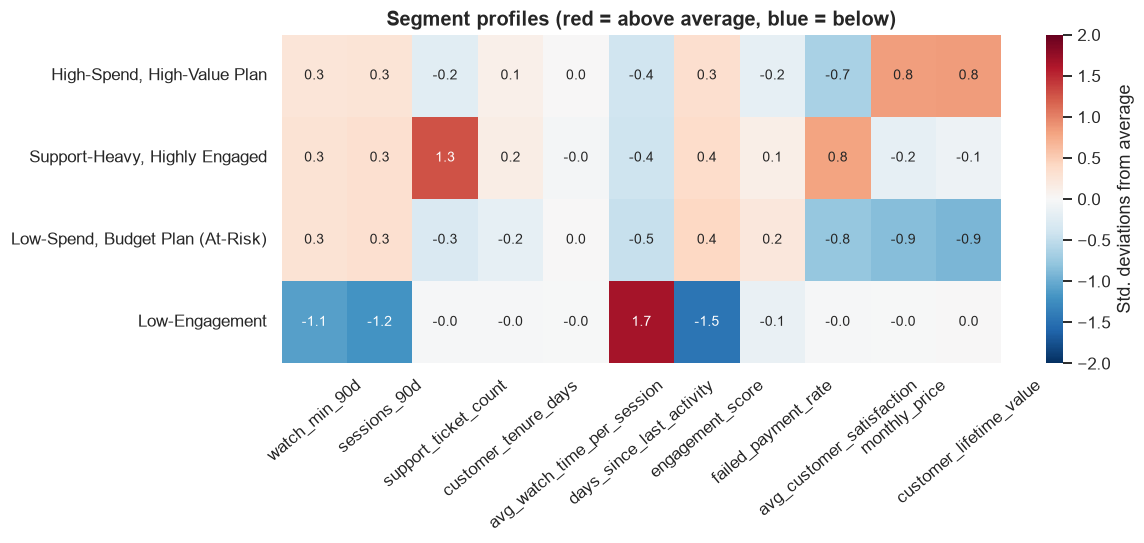

Saved chart: reports\figures\seg_02_segment_profiles.png


In [7]:
# Chart 2 — What makes each segment different (z-scores of the segment averages)
zz = z.copy(); zz.index = [names[i] for i in zz.index]
fig, ax = plt.subplots(figsize=(11, max(3.2, 0.9 * len(zz) + 1.5)))
sns.heatmap(zz, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, cbar_kws={"label": "Std. deviations from average"},
            ax=ax, annot_kws={"size": 9})
ax.set_title("Segment profiles (red = above average, blue = below)"); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=40)
finish(2, "segment_profiles", fig)

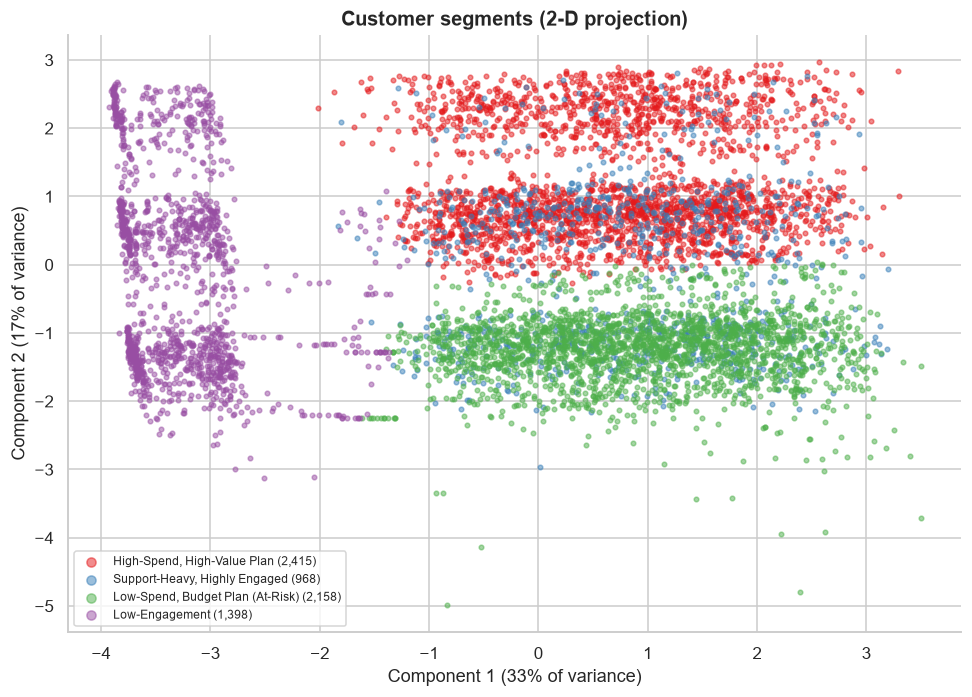

Saved chart: reports\figures\seg_03_segments_pca.png


In [8]:
# Chart 3 — The segments in two dimensions (PCA of the standardised features)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(Z)
palette = sns.color_palette("Set1", n_colors=K)
fig, ax = plt.subplots(figsize=(9, 6.5))
for sid in sorted(names):
    m = (train.segment_id == sid).values
    ax.scatter(P[m, 0], P[m, 1], s=9, alpha=0.5, color=palette[sid], label=f"{names[sid]} ({m.sum():,})")
ax.set_xlabel(f"Component 1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"Component 2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Customer segments (2-D projection)"); ax.legend(fontsize=8, markerscale=2, loc="best")
finish(3, "segments_pca", fig)

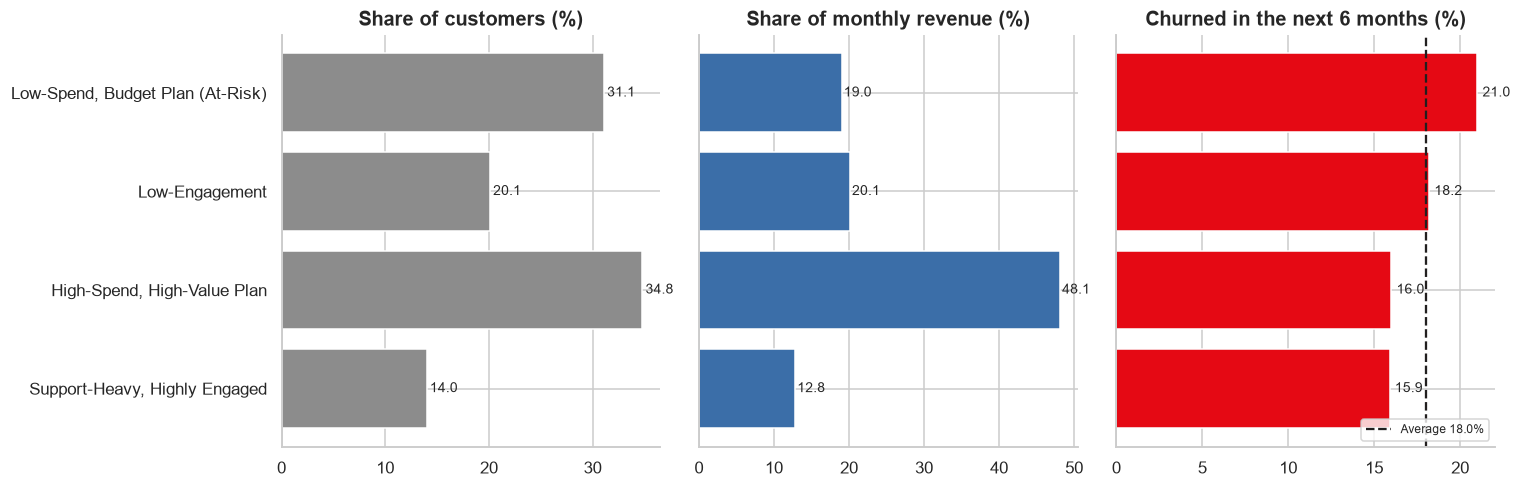

Saved chart: reports\figures\seg_04_segment_size_revenue_churn.png


In [9]:
# Chart 4 — Size, revenue and churn of each segment
order = profile.sort_values("churn_next_6m_%", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
labels = order.segment.tolist()
axes[0].barh(labels, order["share_%"], color=GREY); axes[0].set_title("Share of customers (%)")
axes[1].barh(labels, order["MRR_share_%"], color=BLUE); axes[1].set_title("Share of monthly revenue (%)")
axes[2].barh(labels, order["churn_next_6m_%"], color=NETFLIX_RED); axes[2].axvline(base * 100, color=DARK, ls="--", label=f"Average {base:.1%}")
axes[2].set_title("Churned in the next 6 months (%)"); axes[2].legend(loc="lower right", fontsize=8)
for ax, col in zip(axes, ["share_%", "MRR_share_%", "churn_next_6m_%"]):
    for y, v in enumerate(order[col]): ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=9)
axes[0].invert_yaxis()
finish(4, "segment_size_revenue_churn", fig)

## 5 · Segment every active customer today, and save

In [10]:
seg_model = Pipeline([("prep", prep), ("kmeans", kmeans)])
now_ids = seg_model.predict(now[SEG_FEATURES])
segments_now = pd.DataFrame({"segment_id": now_ids, "segment": [names[i] for i in now_ids]}, index=now.index)
segments_now.to_csv(PROCESSED / "customer_segments_current.csv")

joblib.dump(seg_model, MODELS / "segmentation_model.joblib")
config = {"k": K, "features": SEG_FEATURES, "names": {int(k): v for k, v in names.items()},
          "train_cutoff": json.load(open(PROCESSED / "feature_meta.json"))["train_cutoff"],
          "silhouette": float(silhouette_score(Z, kmeans.labels_, sample_size=3000, random_state=RANDOM_STATE)),
          "stability_ari": float(ari)}
json.dump(config, open(MODELS / "segmentation_config.json", "w"), indent=2)
profile.to_json(REPORTS / "segment_profiles.json", orient="records", indent=2)

print("Saved models/segmentation_model.joblib, models/segmentation_config.json, reports/segment_profiles.csv")
print("Saved data/processed/customer_segments_current.csv\n")
print(segments_now.segment.value_counts().to_string())

Saved models/segmentation_model.joblib, models/segmentation_config.json, reports/segment_profiles.csv
Saved data/processed/customer_segments_current.csv

segment
High-Spend, High-Value Plan         2111
Low-Spend, Budget Plan (At-Risk)    1850
Support-Heavy, Highly Engaged       1085
Low-Engagement                       963


## 6 · Reading the result

In [11]:
from scipy.stats import chi2_contingency
chi2, p_value, _, _ = chi2_contingency(pd.crosstab(train.segment_id, train[TARGET]))
hi = profile.sort_values("churn_next_6m_%", ascending=False).iloc[0]; lo = profile.sort_values("churn_next_6m_%").iloc[0]
top_rev = profile.sort_values("MRR_share_%", ascending=False).iloc[0]
print(f'''SEGMENTATION SUMMARY
- {K} segments (silhouette {config["silhouette"]:.2f}; stability across random starts {ari:.2f}). Silhouette is modest because customer behaviour is a continuum,
  not tight groups; the segments are best read as useful lenses rather than natural species.
- Most fragile: "{hi.segment}" ({hi["share_%"]:.0f}% of customers) churned at {hi["churn_next_6m_%"]:.1f}% vs {base:.1%} on average.
- Most stable: "{lo.segment}" ({lo["share_%"]:.0f}% of customers) churned at {lo["churn_next_6m_%"]:.1f}%.
- Largest revenue share: "{top_rev.segment}" ({top_rev["MRR_share_%"]:.0f}% of monthly revenue).
- Do the segments really differ in churn? Chi-square test p = {p_value:.4f}: {"yes, more than chance would allow" if p_value < 0.05 else "not clearly, so treat the churn differences with caution"}.
- Segments were fitted on the 2025-12-31 snapshot, so these churn rates are real outcomes the segmentation did not see.
''')

SEGMENTATION SUMMARY
- 4 segments (silhouette 0.20; stability across random starts 1.00). Silhouette is modest because customer behaviour is a continuum,
  not tight groups; the segments are best read as useful lenses rather than natural species.
- Most fragile: "Low-Spend, Budget Plan (At-Risk)" (31% of customers) churned at 21.0% vs 18.0% on average.
- Most stable: "Support-Heavy, Highly Engaged" (14% of customers) churned at 15.9%.
- Largest revenue share: "High-Spend, High-Value Plan" (48% of monthly revenue).
- Do the segments really differ in churn? Chi-square test p = 0.0000: yes, more than chance would allow.
- Segments were fitted on the 2025-12-31 snapshot, so these churn rates are real outcomes the segmentation did not see.

